# Part 2 : MVPA: temporal ICA (variant 2)

**Goal:** find spatial patterns of brain activity in a data-driven way, then check which of them correspond to the story and math conditions modelled by the GLM in Part 1.

**Data:** HCP run `tfMRI_LANGUAGE_LR`, one subject, 306 volumes, TR = 0.72 s. We use the output of the Part 1 preprocessing (same data as the GLM): first 10 volumes removed, motion-corrected (MCFLIRT) and smoothed (6 mm FWHM), on the MNI 2 mm grid. The subject listens to short stories and to arithmetic problems, and answers each with a button press.

## Assignment (Variant 2)

1. Apply ICA on the fMRI run, *one timepoint = one sample* 
2. Select the number of components and justify it; show each spatial map separately, axial view only 
3. Correlate the time courses of the first 10 ICs with the GLM regressors of Part 1; relate the results to the maps



# Data preparation
1. **Setup**: imports, paths and all parameters in one place
2. **Load and check** the fMRI, the T1 and the events
3. **Brain mask**
4. **Global signal**: quality check of the preprocessed run
5. **Data matrix X**: timepoints × voxels, cleaned; **each timepoint is one sample**

*Note: the sign and the order of ICA components are arbitrary. Components must be identified by their time course and map, never by their number.*

## 1. Setup
All imports, paths and analysis parameters are defined here, so every choice is visible in one place and easy to report.

In [ ]:
import os
import os.path as op
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

from nilearn import plotting, signal
from nilearn.image import index_img, new_img_like
from nilearn.masking import compute_brain_mask
from nilearn.maskers import NiftiMasker
from nilearn.glm.first_level import make_first_level_design_matrix

# Paths
DATA_DIR    = "../data/miniproject_2026_final"
PREPROC_DIR = "../outputs"                     # outputs of 01_preprocessing
FUNC_PATH   = op.join(PREPROC_DIR, "func/tfMRI_LANGUAGE_LR_trim_moco_smoothed-6mm.nii.gz")
T1_PATH     = op.join(PREPROC_DIR, "anat/T1w_mni_final.nii.gz")
MOTION_PATH = op.join(PREPROC_DIR, "func/tfMRI_LANGUAGE_LR_trim_moco.par")
ONSETS_PATH = op.join(DATA_DIR, "fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR_task_onsets.csv")
OUT_DIR     = "../outputs/partie2"

# Parameters 
TR          = 0.72    # repetition time (s), checked against the header in §2
N_TOTAL     = 316     # volumes of the original run
N_DROP      = 10      # already removed in Part 1 (fslroi); only used to align the regressors
HIGH_PASS   = 0.01    # Hz, cutoff of the cosine drift regressors (~100 s period)
HRF_MODEL   = "glover"   # must be the same HRF as the Part 1 GLM
SMOOTH_FWHM = None    # already smoothed (6 mm) in Part 1
SEED        = 0       # random seed for FastICA (reproducibility)

os.makedirs(OUT_DIR, exist_ok=True)
for p in [T1_PATH, FUNC_PATH, MOTION_PATH, ONSETS_PATH]:
        assert op.exists(p), f"File not found: {p}"
print("All input files found.")

All input files found.


## 2. Load and check the data
We load the three inputs and check that they are what we expect:
- **fMRI**: should be 91 × 109 × 91 voxels of 2 mm, the standard MNI 2 mm grid. with 306 volumes (316 acquired − 10 removed in Part 1). No registration is needed for this part.
- **TR**: the header value must match the `TR` used everywhere else.
- **T1**: skull-stripped T1 registered to MNI in Part 1, only used as the background of the figures.
- **Events**: one row per event, with `onset`, `duration` and `trial_type`, the format nilearn expects.

In [2]:
from nilearn import datasets
t1 = nib.load(T1_PATH) if op.exists(T1_PATH) else datasets.load_mni152_template(resolution=1)
img = nib.load(FUNC_PATH)
events = pd.read_csv(ONSETS_PATH)
n_vols = img.shape[-1]

print("fMRI shape :", img.shape, "| voxel size :", img.header.get_zooms()[:3], "mm")
print("T1 shape   :", t1.shape, "| voxel size :", t1.header.get_zooms()[:3], "mm")
print("Events     :", events.shape, "| columns :", events.columns.tolist())

# Checks
assert img.shape[:3] == (91, 109, 91), "fMRI is not on the MNI 2 mm grid"
assert np.isclose(float(img.header.get_zooms()[3]), TR), "TR in header differs from TR"
assert {"onset", "duration", "trial_type"} <= set(events.columns)
assert n_vols == N_TOTAL - N_DROP, f"Expected {N_TOTAL - N_DROP} volumes, got {n_vols}"
print(f"OK: MNI 2 mm grid, TR = {TR} s, {n_vols} volumes = {n_vols * TR:.1f} s of recording")
events.head(15)

fMRI shape : (91, 109, 91, 306) | voxel size : (np.float32(2.0), np.float32(2.0), np.float32(2.0)) mm
T1 shape   : (182, 218, 182) | voxel size : (np.float32(1.0), np.float32(1.0), np.float32(1.0)) mm
Events     : (59, 3) | columns : ['onset', 'duration', 'trial_type']
OK: MNI 2 mm grid, TR = 0.72 s, 306 volumes = 220.3 s of recording


,onset,duration,trial_type
0,0.241,28.270,story
1,0.241,20.445,present_story
2,21.192,1.161,question_story
3,25.550,2.961,response_story
4,28.696,0.727,cue
5,30.095,5.667,present_math
6,30.095,12.241,math
7,35.946,3.391,question_math
8,39.371,2.965,response_math
9,42.570,5.453,present_math


### Event structure
The events are **hierarchical**: each block event contains three successive sub-phases.

| Block | Sub-phases | Meaning |
|---|---|---|
| `story` (~28 s) | `present_story` → `question_story` → `response_story` | one story = one whole block (4 in total) |
| `math` (~12 s) | `present_math` → `question_math` → `response_math` | one arithmetic problem; a math block chains several of them (9 in total) |

- **present**: listening to the story or to the arithmetic problem
- **question**: listening to the question / the two answer options
- **response**: button-press window
- **cue**: short signal between blocks announcing the next task

**Consequence:** a block and its own sub-phases must never be in the same GLM, because the same seconds would be counted twice and the regressors would be collinear. The **blocks** `story` and `math` are the main regressors. The sub-phases are kept as a second, separate set of regressors for the correlations in P3, where they give a finer view of the task.

The cell below **checks this structure in the data** instead of assuming it: every block must start with its `present` phase and end with its `response` phase.

In [3]:
print(events["trial_type"].value_counts().to_string(), "\n")

for task in ["story", "math"]:
    blocks = events[events.trial_type == task]
    pres = events[events.trial_type == f"present_{task}"].onset.values
    resp = events[events.trial_type == f"response_{task}"]
    resp_end = (resp.onset + resp.duration).values
    start_ok = np.allclose(blocks.onset.values, pres, atol=0.05)
    end_ok = np.allclose((blocks.onset + blocks.duration).values, resp_end, atol=0.05)
    print(f"{task:5s}: {len(blocks)} blocks | start = present_{task}: {start_ok} | end = response_{task}: {end_ok}")

last_end = (events.onset + events.duration).max()
print(f"\nRun length: {N_TOTAL * TR:.1f} s | last event ends at {last_end:.1f} s")


trial_type
present_math      9
math              9
question_math     9
response_math     9
cue               7
story             4
present_story     4
question_story    4
response_story    4 

story: 4 blocks | start = present_story: True | end = response_story: True
math : 9 blocks | start = present_math: True | end = response_math: True

Run length: 227.5 s | last event ends at 232.2 s


## 3. Brain mask
Only voxels inside the brain are analysed: voxels outside contain no signal and would only add noise (and edge components) to the ICA. The mask combines:
- nilearn's **MNI brain template mask** on the fMRI grid (`compute_brain_mask`), and
- voxels whose signal **actually varies over time** (voxels outside the brain carry no signal, and constant voxels cannot be z-scored).

Voxels in the mask: 216734


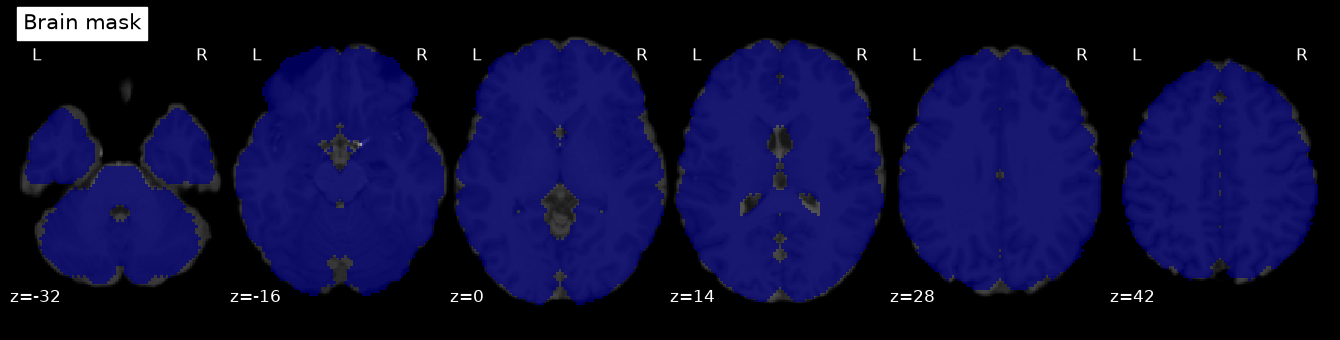

In [4]:
data = img.get_fdata(dtype=np.float32)             # (91, 109, 91, 316)
template_mask = compute_brain_mask(img, threshold=0.5).get_fdata().astype(bool)
mask_img = new_img_like(img.slicer[..., 0], template_mask & (data.std(axis=-1) > 0))
print("Voxels in the mask:", int(mask_img.get_fdata().sum()))

plotting.plot_roi(mask_img, bg_img=t1, display_mode="z", cut_coords=6, title="Brain mask")
plt.show()

## 4. Global signal and non-steady-state volumes
The first 10 non-steady-state volumes were already removed in Part 1. We plot the mean brain signal over the 306 remaining volumes to check that no initial transient or abrupt jump is left, since the ICA would otherwise spend components modelling it.


First 6 volumes (% from median): [0.27 0.16 0.19 0.26 0.28 0.28]


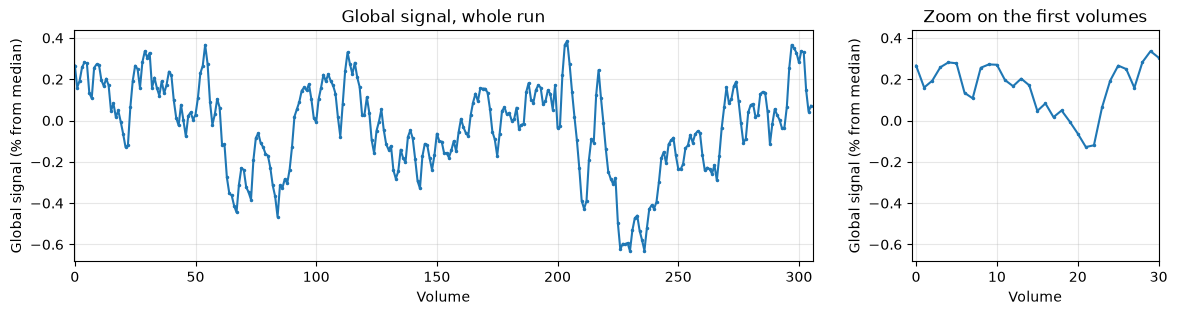

In [5]:
global_signal = data[mask_img.get_fdata().astype(bool)].mean(axis=0)
del data                                            # free ~1 GB of memory
pct = 100 * (global_signal / np.median(global_signal) - 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 3), gridspec_kw={"width_ratios": [3, 1]})
for a, xmax in zip(ax, [n_vols, 30]):
    a.plot(np.arange(n_vols), pct, ".-", ms=3)
    a.set(xlim=(-0.5, xmax), xlabel="Volume", ylabel="Global signal (% from median)")
    a.grid(alpha=0.3)
ax[0].set_title("Global signal, whole run"); ax[1].set_title("Zoom on the first volumes")

print("First 6 volumes (% from median):", np.round(pct[:6], 2))

The global signal stays within a narrow range over the whole run, and the first volumes (0.16–0.28 % from the median) are in line with the rest: no initial transient or abrupt jump is left after the preprocessing of Part 1.

The event onsets are timed from the start of the original 316-volume run. We therefore build the regressors on these 316 volumes and then remove their first 10 rows, exactly like the 10 volumes removed from the data in Part 1, so that data and regressors stay aligned (306 volumes).


In [6]:
frame_times = np.arange(N_TOTAL) * TR        # original run timing: event onsets stay valid

# Block regressors + cosine drifts
block_events = events[events.trial_type.isin(["story", "math"])]
dm = make_first_level_design_matrix(frame_times, block_events, hrf_model=HRF_MODEL,
                                    drift_model="cosine", high_pass=HIGH_PASS)
drift_cols = [c for c in dm.columns if c.startswith("drift")]

img_clean = img                              # already trimmed in Part 1
dm_clean  = dm.iloc[N_DROP:]
ft_clean  = frame_times[N_DROP:]
print("fMRI:", img_clean.shape, "| block design:", dm_clean.shape)


fMRI: (91, 109, 91, 306) | block design: (306, 7)


## 5. Data matrix X: one timepoint = one sample
`NiftiMasker` turns the 4D image into a 2D matrix and cleans it:

| Step | What it does | Why |
|---|---|---|
| **Mask** | keeps the brain voxels | no signal outside the brain |
| **Smoothing** (6 mm) | none here: already done in Part 1 (6 mm FWHM) | avoids smoothing the data twice |
| **Detrend + cosine drifts** | removes linear trends and slow drifts (> 100 s) | otherwise slow drift would be the largest "pattern" in the data. Cosine regression was preferred over a high-pass filter, which created edge effects at the start and end of the run |
| **z-score** each voxel | mean 0, standard deviation 1 | no voxel dominates just because it is brighter or noisier |

**Result:** X has shape **306 timepoints × 216,734 voxels**. Each **row** is one brain volume (one timepoint) and is one **sample**; each **column** is one voxel. Running ICA on this X makes the **time courses** independent (temporal ICA).

In [7]:
masker = NiftiMasker(
    mask_img=mask_img,
    smoothing_fwhm=SMOOTH_FWHM,
    detrend=True,
    standardize="zscore_sample",
    t_r=TR,
    dtype="float32",
)
X = masker.fit_transform(img_clean, confounds=dm_clean[drift_cols].values)
print("X:", X.shape, "(timepoints x voxels)")

# Checks
print("NaN:", int(np.isnan(X).sum()),
      "| mean ≈ 0:", np.allclose(X.mean(axis=0), 0, atol=1e-3),
      "| std ≈ 1:", np.allclose(X.std(axis=0, ddof=1), 1, atol=1e-2))

X: (306, 216734) (timepoints x voxels)
NaN: 0 | mean ≈ 0: True | std ≈ 1: True


# ICA implementation
6. **PCA of the Data**
7. **Stability of ICA** 
8. **Choice of number of components**
9. **Temporal ICA**
10. **Spatial Maps**


## 6. How many components? PCA of the data

ICA cannot tell by itself how many sources the data contains, so the number of components $n$ has to be chosen. FastICA always starts by **reducing the data with PCA** (the *whitening* step): it keeps the first $n$ principal components, rescales them to unit variance, and then looks for independent components inside that $n$-dimensional space. **Choosing $n$ for ICA therefore amounts to choosing how many PCA dimensions carry signal rather than noise.**

Number of PCA components: 306


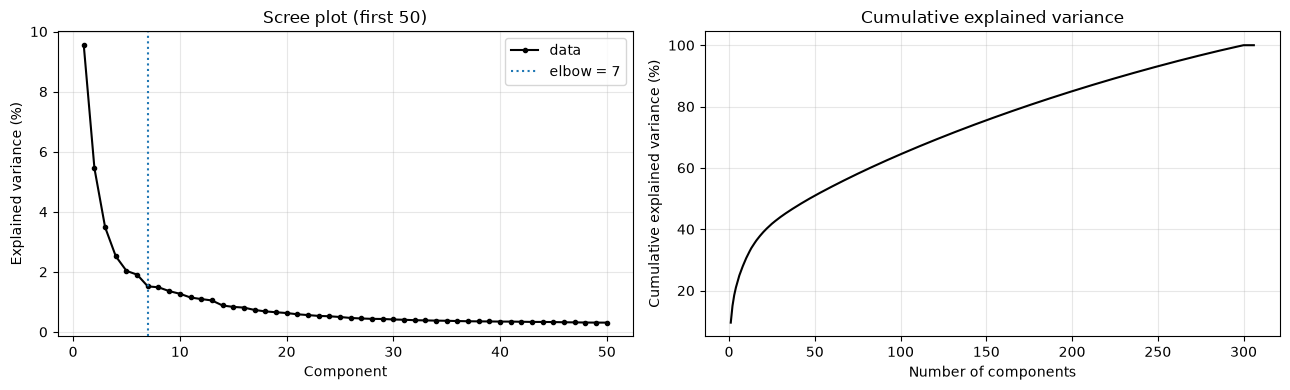

Elbow of the scree plot      : 7 components
  5 components: 23.0% of the variance
 10 components: 30.6% of the variance
 15 components: 35.6% of the variance
 20 components: 39.1% of the variance
 30 components: 44.0% of the variance
 50 components: 50.9% of the variance


In [8]:
from sklearn.decomposition import PCA, FastICA
from scipy.optimize import linear_sum_assignment

# Full PCA of X 
pca = PCA(svd_solver="full", random_state=SEED).fit(X)
ratio = pca.explained_variance_ratio_          # variance explained by each component
cum = np.cumsum(ratio)                         # cumulative explained variance
Z = pca.transform(X)                           # (313, 313) PCA scores, used in §8
print("Number of PCA components:", len(ratio))

# Elbow
K = 50
xk, yk = np.arange(1, K + 1), ratio[:K]
dist = np.abs((yk[-1] - yk[0]) * xk - (K - 1) * yk + K * yk[0] - yk[-1]) / np.hypot(yk[-1] - yk[0], K - 1)
n_elbow = int(xk[np.argmax(dist)])

# Figures
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(xk, 100 * yk, "o-", ms=3, c="k", label="data")
ax[0].axvline(n_elbow, c="tab:blue", ls=":", label=f"elbow = {n_elbow}")
ax[0].set(xlabel="Component", ylabel="Explained variance (%)", title=f"Scree plot (first {K})")
ax[0].legend()
ax[1].plot(np.arange(1, len(cum) + 1), 100 * cum, c="k")
ax[1].set(xlabel="Number of components", ylabel="Cumulative explained variance (%)",
          title="Cumulative explained variance")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(op.join(OUT_DIR, "pca_variance.png"), dpi=150); plt.show()

print(f"Elbow of the scree plot      : {n_elbow} components")
for k in [5, 10, 15, 20, 30, 50]:
    print(f"{k:>3} components: {cum[k - 1]:.1%} of the variance")

## 7. How many components? Stability of ICA

PCA tells how much variance each dimension carries, but not whether ICA can **reliably separate** that variance into components. FastICA starts from a random rotation, so a good test is to run it several times with different random seeds: if the same components come back every time, they reflect real structure; if they change from run to run, ICA is fitting noise. 

For each candidate $n$ we run FastICA with 5 seeds, match the components of each run to those of the first run and report:
- **mean matched |r|**: how similar the runs are on average (1 = identical);
- **fraction of components with |r| > 0.9**: how many components are clearly reproducible;
- **converged runs**: how many runs reached FastICA's stopping criterion before `MAX_ITER`. Non-convergence is common in fMRI and is not by itself a failure: when some of the $n$ dimensions are close to Gaussian noise, there is no unique way to un-mix them, so FastICA keeps rotating them while the non-Gaussian components (task networks, artefacts) are already found. What matters is whether the components are **reproducible**, which is what the two other columns measure.

*Implementation:* ICA is run on the first $n$ PCA scores `Z[:, :n]` instead of X. This is the subspace FastICA itself would whiten X into, so the components are the same, but each run takes seconds instead of re-decomposing the 306 × 216,734 matrix. The final ICA follows Lab 7: PCA to 2n components, then FastICA with n.

Stability is expected to stay high up to some $n$ and then drop: past that point the extra dimensions are mostly noise, and ICA splits them differently on every run.

/Users/arnaud/anaconda3/envs/nssp-vm/lib/python3.13/site-packages/sklearn/decomposition/_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/Users/arnaud/anaconda3/envs/nssp-vm/lib/python3.13/site-packages/sklearn/decomposition/_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/Users/arnaud/anaconda3/envs/nssp-vm/lib/python3.13/site-packages/sklearn/decomposition/_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/Users/arnaud/anaconda3/envs/nssp-vm/lib/python3.13/site-packages/sklearn/decomposition/_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(
/Users/arnaud/anaconda3/envs/nssp-vm/lib/python3.13/site-pac

,cumulative variance (%),mean matched |r|,fraction |r| > 0.9,converged runs
n,,,,
10,30.600000,0.859,0.60,5/5
11,31.700001,0.981,0.95,5/5
12,32.799999,1.000,1.00,5/5
13,33.900002,0.918,0.79,4/5
14,34.700001,0.917,0.73,2/5
15,35.599998,0.837,0.53,4/5
16,36.400002,0.939,0.78,5/5
18,37.799999,0.812,0.46,5/5
20,39.099998,0.763,0.40,1/5


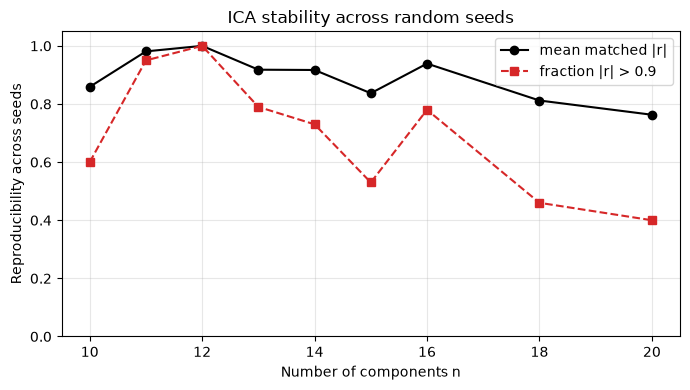

In [9]:
CANDIDATES = [10, 11, 12, 13, 14, 15, 16, 18, 20]
SEEDS = range(5)
MAX_ITER = 5000   # fixed: together with SEED, makes every run reproducible

def run_ica(Zn, seed):
    ica = FastICA(n_components=Zn.shape[1], whiten="unit-variance",
                  max_iter=MAX_ITER, random_state=seed)
    S = ica.fit_transform(Zn)
    return S, ica.n_iter_ < MAX_ITER

def matched_corr(S_ref, S):
    n = S_ref.shape[1]
    R = np.abs(np.corrcoef(S_ref.T, S.T)[:n, n:])
    rows, cols = linear_sum_assignment(-R)     # best one-to-one matching
    return R[rows, cols]

table = []
for n in CANDIDATES:
    runs = [run_ica(Z[:, :n], s) for s in SEEDS]
    r = np.concatenate([matched_corr(runs[0][0], S) for S, _ in runs[1:]])
    table.append({"n": n,
                  "cumulative variance (%)": round(100 * cum[n - 1], 1),
                  "mean matched |r|": round(r.mean(), 3),
                  "fraction |r| > 0.9": round((r > 0.9).mean(), 2),
                  "converged runs": f"{sum(c for _, c in runs)}/{len(runs)}"})
stab = pd.DataFrame(table).set_index("n")
stab.to_csv(op.join(OUT_DIR, "ica_stability.csv"))
display(stab)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(stab.index, stab["mean matched |r|"], "o-", c="k", label="mean matched |r|")
ax.plot(stab.index, stab["fraction |r| > 0.9"], "s--", c="tab:red", label="fraction |r| > 0.9")
ax.set(xlabel="Number of components n", ylabel="Reproducibility across seeds",
       ylim=(0, 1.05), title="ICA stability across random seeds")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(op.join(OUT_DIR, "ica_stability.png"), dpi=150); plt.show()

## 8. Choice of the number of components

The choice combines our two criteria:
1. **Elbow** : $n$ should be *after* the elbow, so the structured variance is kept.
2. **Stability** : $n$ should be in the range where ICA gives the same components across seeds; take the largest such $n$, so that distinct networks are not merged.

We retained **n = 12** components. The scree plot has an elbow at 7 components, and n = 12 is the value for which ICA was perfectly reproducible across 5 random seeds (mean matched |r| = 1.000, 100 % of the components with |r| > 0.9, 5/5 runs converged). Stability increases up to this value (n = 10: 0.859, 60 %; n = 11: 0.981, 95 %), because with too few dimensions distinct sources have to be merged and each seed merges them differently. It drops immediately above it (n = 13: 0.918, 79 %; n = 14: 0.917, 73 %, 2/5 converged), where the extra dimensions are mostly noise that ICA splits differently on every run.

The 12 retained components explain 32.8 % of the variance. This low value is expected in fMRI, where most of the variance is unstructured noise spread over the remaining components.


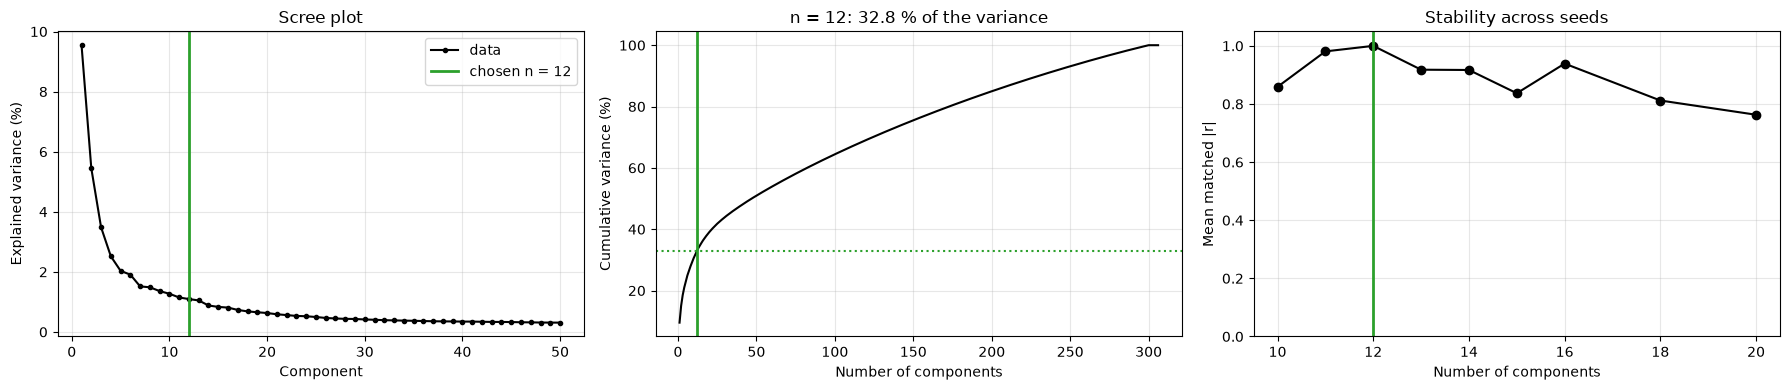

In [10]:
N_COMP = 12       
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(xk, 100 * yk, "o-", ms=3, c="k", label="data")
ax[0].axvline(N_COMP, c="tab:green", lw=2, label=f"chosen n = {N_COMP}")
ax[0].set(xlabel="Component", ylabel="Explained variance (%)", title="Scree plot"); ax[0].legend()
ax[1].plot(np.arange(1, len(cum) + 1), 100 * cum, c="k")
ax[1].axvline(N_COMP, c="tab:green", lw=2)
ax[1].axhline(100 * cum[N_COMP - 1], c="tab:green", ls=":")
ax[1].set(xlabel="Number of components", ylabel="Cumulative variance (%)",
          title=f"n = {N_COMP}: {100 * cum[N_COMP - 1]:.1f} % of the variance")
ax[2].plot(stab.index, stab["mean matched |r|"], "o-", c="k")
ax[2].axvline(N_COMP, c="tab:green", lw=2)
ax[2].set(xlabel="Number of components", ylabel="Mean matched |r|", ylim=(0, 1.05),
          title="Stability across seeds")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(op.join(OUT_DIR, "n_components_choice.png"), dpi=150); plt.show()

## 9. Temporal ICA

FastICA is applied to **X (306 timepoints × voxels)**: each row (one brain volume) is one **sample**, as required by Practical 1. It writes the data as

$$X \approx S\,A \qquad S:\ 306 \times n \ \text{(time courses)}, \qquad A:\ n \times n_\text{voxels} \ \text{(spatial maps)}$$

and finds the $S$ whose columns are **as statistically independent as possible** (as non-Gaussian as possible). Because the samples are timepoints, it is the **time courses** that are made independent: this is *temporal* ICA. The maps are not constrained.

In [11]:
# PCA to 2n components before ICA
N_PCA = 2 * N_COMP
pca_red = PCA(n_components=N_PCA, random_state=SEED)
Z_red = pca_red.fit_transform(X)                        # (306, 24) PCA scores

ica = FastICA(n_components=N_COMP, whiten="unit-variance",
              max_iter=MAX_ITER, random_state=SEED)               
timecourses = ica.fit_transform(Z_red)                  # (306, 12)
spatial_maps = ica.mixing_.T @ pca_red.components_      # (12, n_voxels): back to voxel space


converged = ica.n_iter_ < MAX_ITER
print(f"Iterations: {ica.n_iter_} / {MAX_ITER} -> {'converged' if converged else 'stopped at MAX_ITER (see text)'}")
print("Time courses:", timecourses.shape, "| spatial maps:", spatial_maps.shape)

# Sign convention: strongest voxel of each map positive (map and time course flipped together)
for i in range(N_COMP):
    if spatial_maps[i, np.argmax(np.abs(spatial_maps[i]))] < 0:
        spatial_maps[i] *= -1
        timecourses[:, i] *= -1


# Save, so the ICA does not have to be rerun every time
np.save(op.join(OUT_DIR, f"ica{N_COMP}_timecourses.npy"), timecourses)
np.save(op.join(OUT_DIR, f"ica{N_COMP}_spatial_maps.npy"), spatial_maps)
print("Saved in", OUT_DIR)

Iterations: 29 / 5000 -> converged
Time courses: (306, 12) | spatial maps: (12, 216734)
Saved in ../outputs/partie2


FastICA converged in 29 iterations, far below `MAX_ITER`, consistent with the perfect stability found at n = 12. 

## 10. Spatial maps, one per component, axial view only
Maps are z-scored over voxels and shown at |z| > 2.5; this threshold is a display choice, not a statistical test.

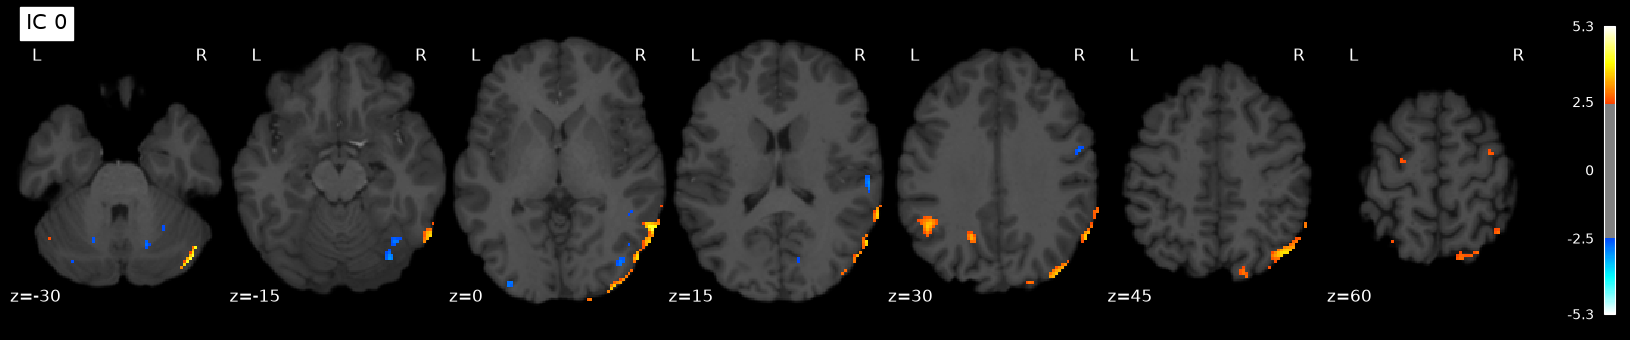

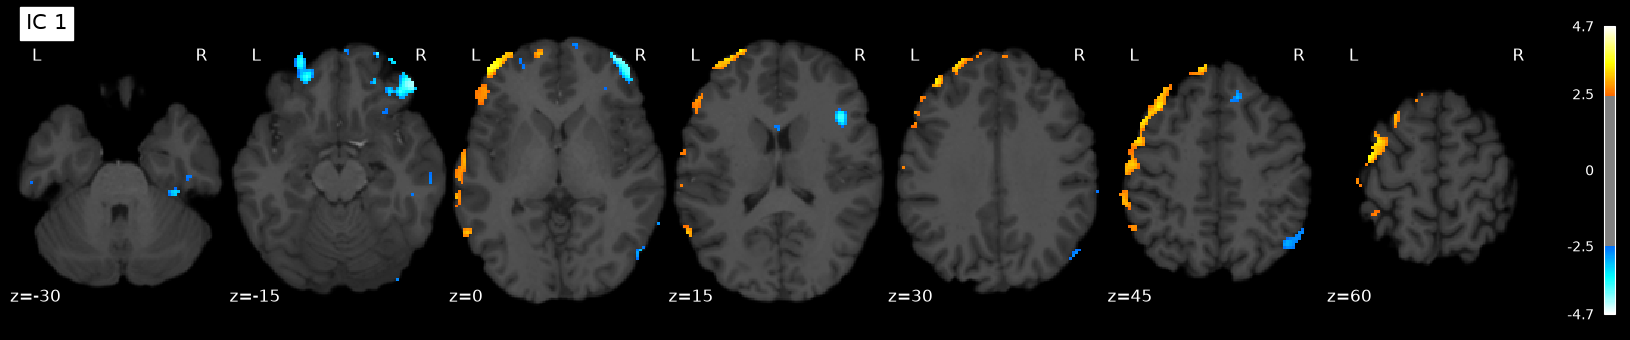

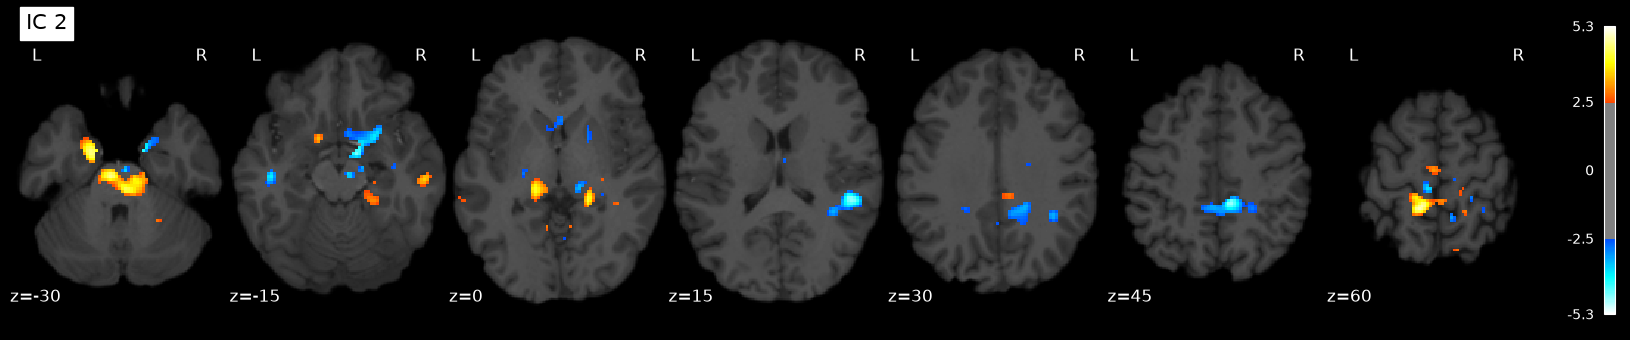

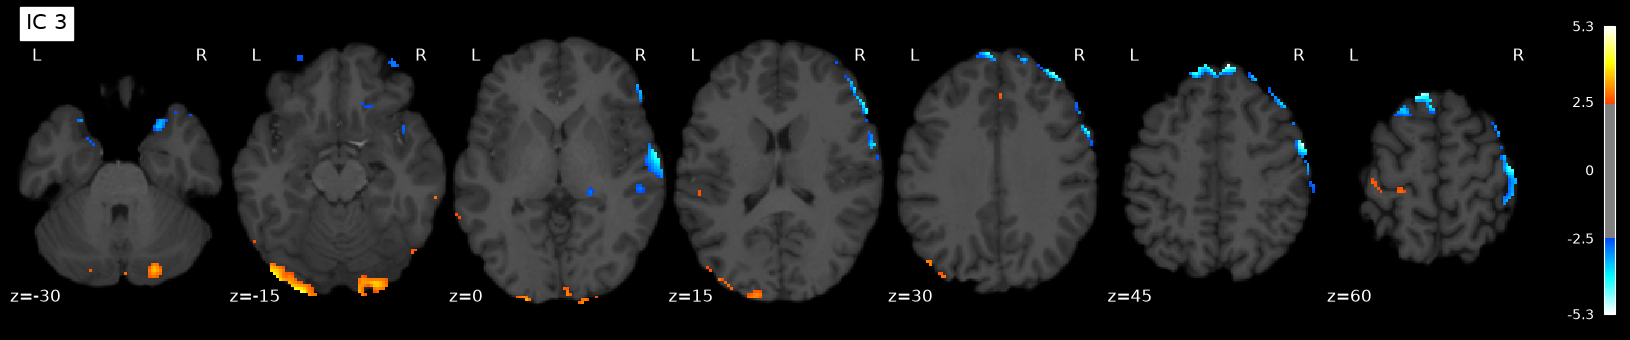

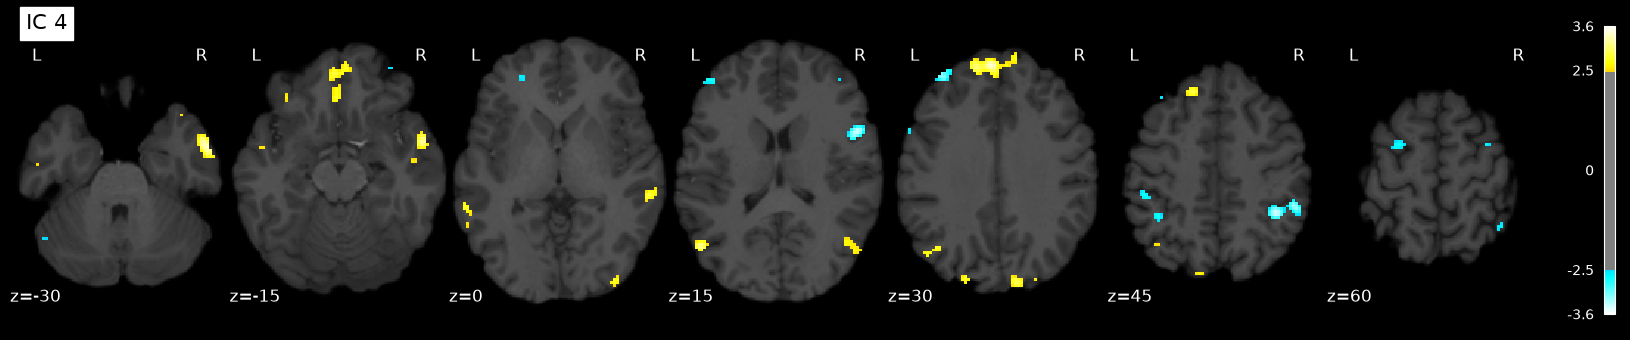

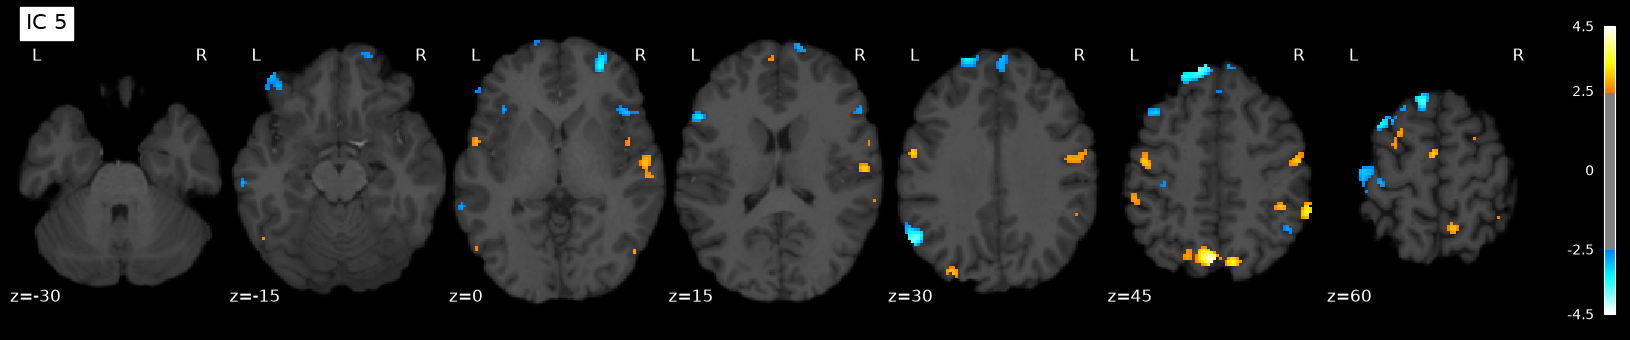

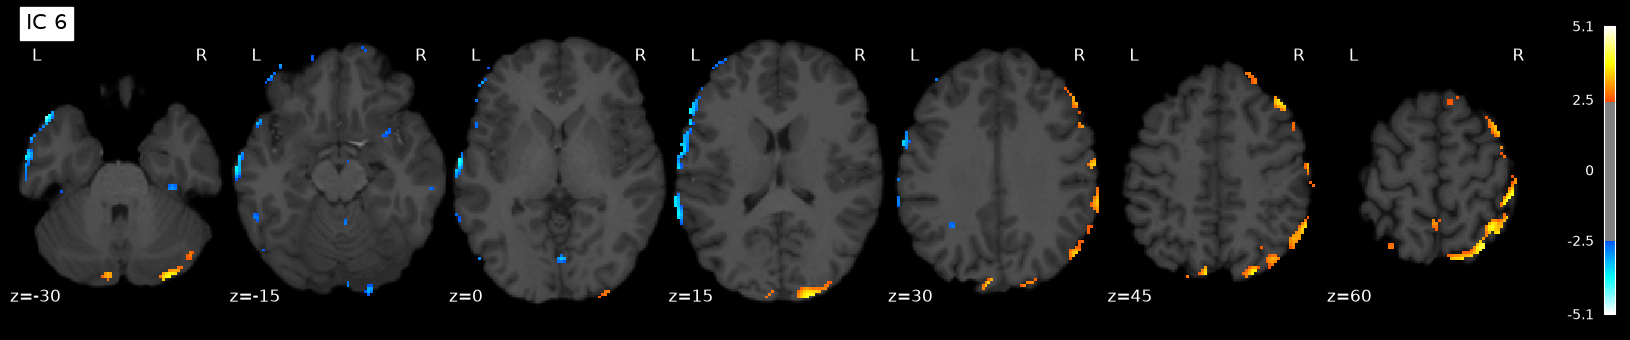

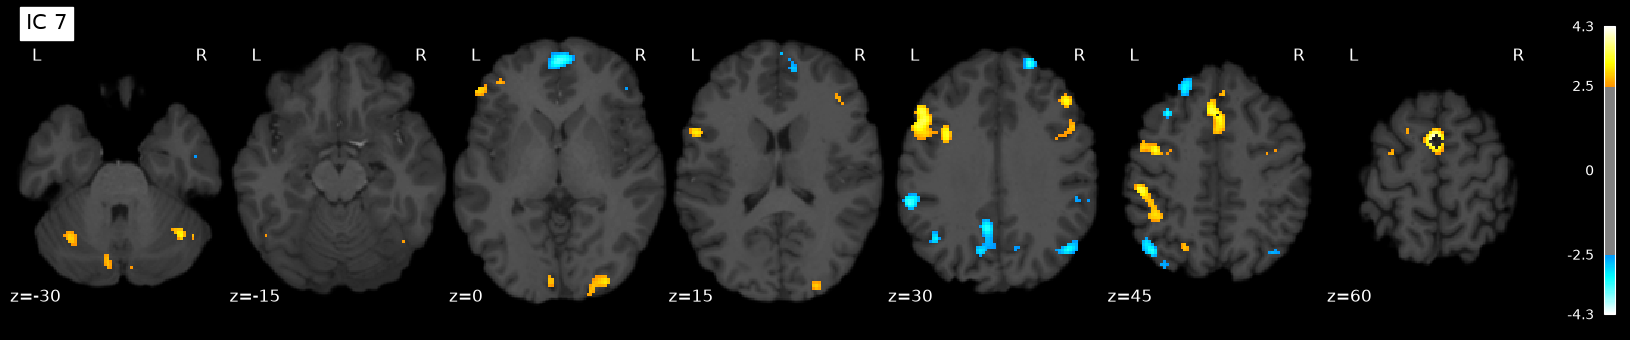

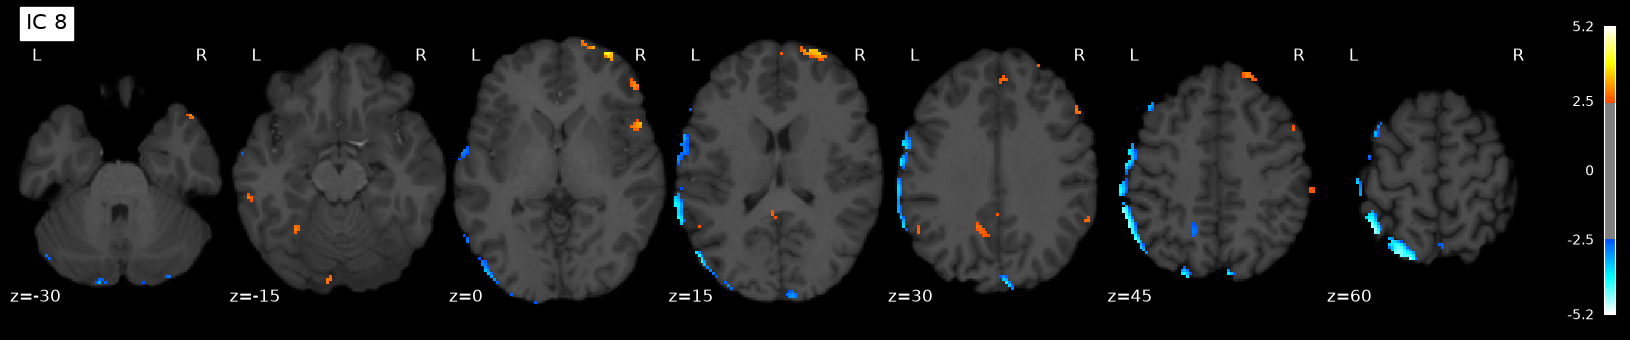

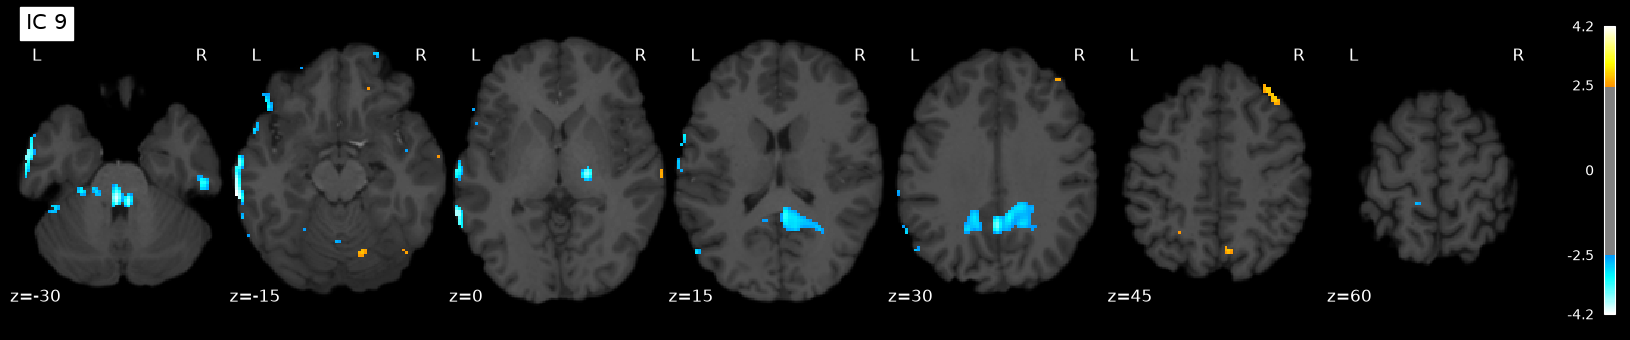

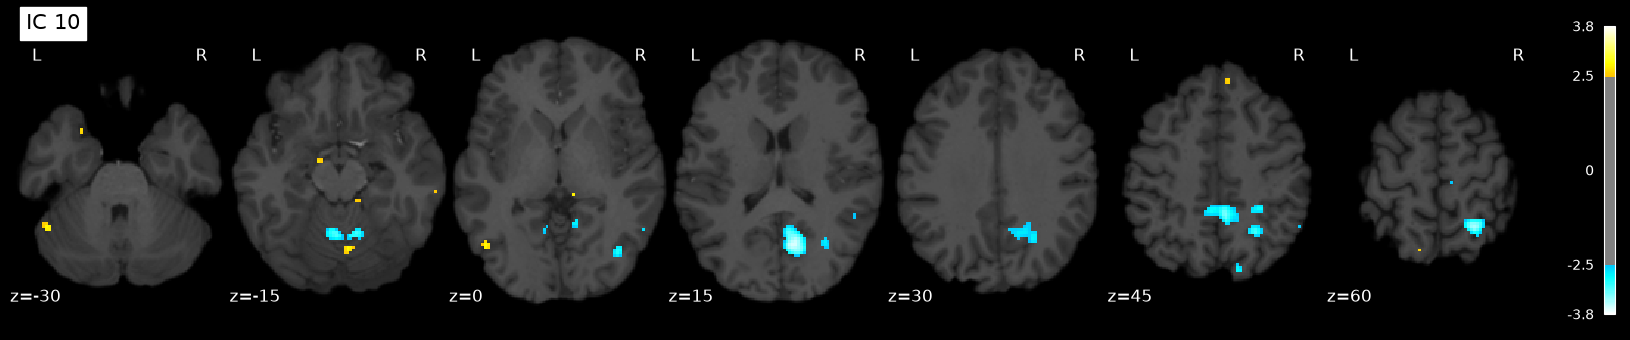

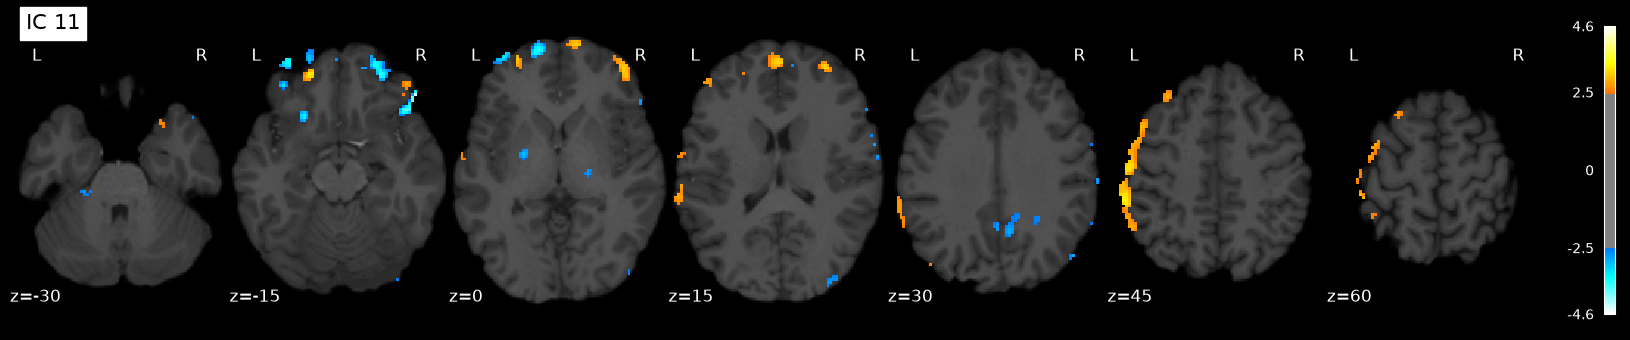

Summary figure saved: ../outputs/partie2/ica12_all_axial.png


In [12]:
from scipy.stats import zscore

THRESH = 2.5                                   # |z| display threshold
CUTS = [-30, -15, 0, 15, 30, 45, 60]           # axial slices (mm, MNI)

maps_z = zscore(spatial_maps, axis=1)          # each map: mean 0, SD 1 over voxels
maps_img = masker.inverse_transform(maps_z)    # 4D image (91, 109, 91, N_COMP)

# One figure per component
for i in range(N_COMP):
    disp = plotting.plot_stat_map(
        index_img(maps_img, i), bg_img=t1, display_mode="z", cut_coords=CUTS,
        threshold=THRESH, colorbar=True, black_bg=True, title=f"IC {i}",
    )
    disp.savefig(op.join(OUT_DIR, f"ica{N_COMP}_IC{i:02d}_axial.png"), dpi=150)
    plt.show()

# Summary figure (appendix)
fig = plt.figure(figsize=(14, 1.9 * N_COMP))
for i in range(N_COMP):
    ax = fig.add_subplot(N_COMP, 1, i + 1)
    plotting.plot_stat_map(
        index_img(maps_img, i), bg_img=t1, display_mode="z", cut_coords=CUTS,
        threshold=THRESH, colorbar=False, black_bg=True, title=f"IC {i}", axes=ax,
    )
fig.savefig(op.join(OUT_DIR, f"ica{N_COMP}_all_axial.png"), dpi=150, bbox_inches="tight")
plt.close(fig)
print("Summary figure saved:", op.join(OUT_DIR, f"ica{N_COMP}_all_axial.png"))

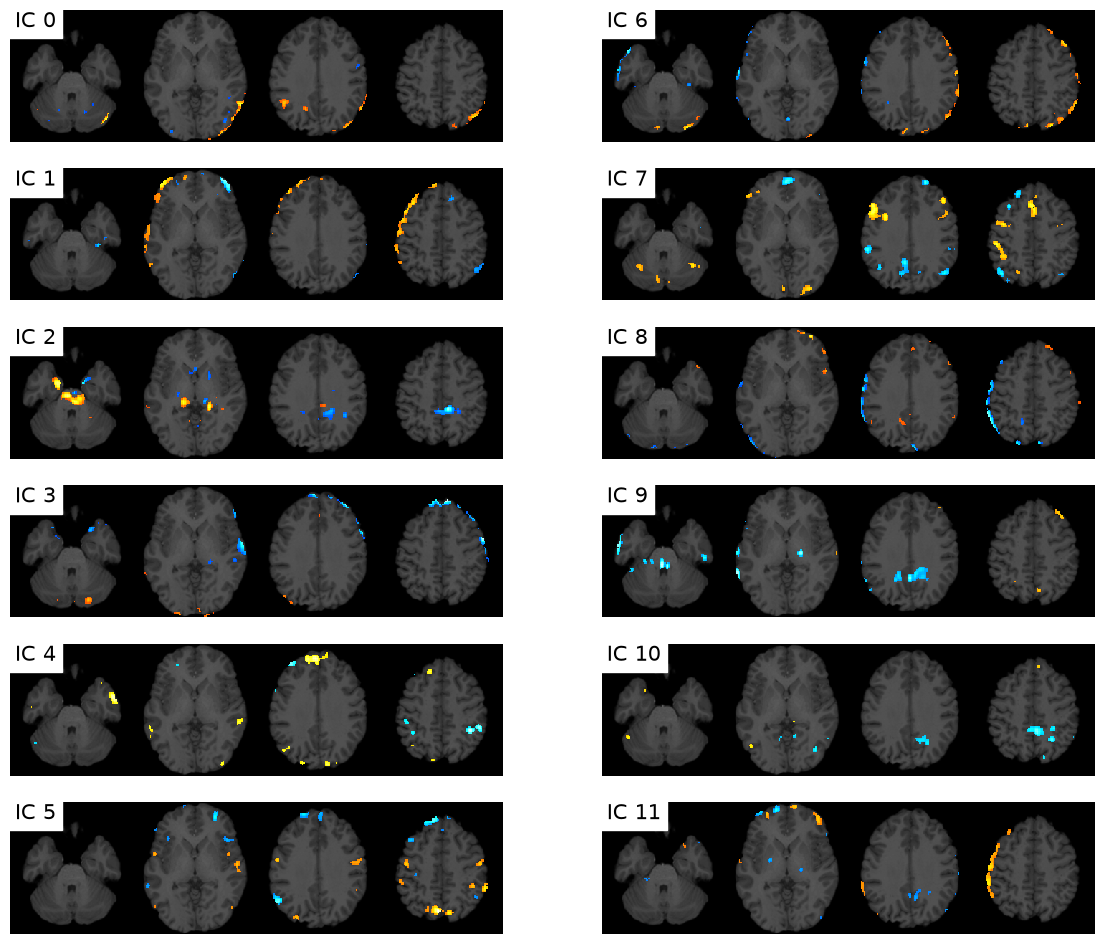

In [13]:
# All components, 4 slices each (appendix)
fig, axes = plt.subplots(6, 2, figsize=(14, 12))
for i, ax in enumerate(axes.T.ravel()):          # IC 0-5 left column, IC 6-11 right column
    plotting.plot_stat_map(masker.inverse_transform(maps_z[i]), bg_img=t1,
                           display_mode="z", cut_coords=[-30, 0, 30, 45],
                           threshold=THRESH, axes=ax, colorbar=False,
                           annotate=False, black_bg=True, title=f"IC {i}")
fig.savefig(op.join(OUT_DIR, f"ica{N_COMP}_compact_axial.png"), dpi=200, bbox_inches="tight")
plt.show()

### Interpretation of the maps
Based on the maps and the time courses (§12–13), the components fall into four groups:
- **Task-related: IC 4, 5 and 7.** IC 4 is positive mainly in the temporal lobes and medial prefrontal cortex and negative in the parietal cortex, which resembles the story > math and math > story maps of Part 1. The negative pole of IC 7, in medial parietal and frontal regions, may be the default-mode network.
- **Motion or edge artefacts: IC 0, 1, 3, 6, 8 and 11.** Their maps form a rim along the edge of the brain, the typical signature of head motion, and their time courses follow the motion parameters (§13).
- **Likely physiological: IC 2 and IC 10.** IC 2 lies in the brainstem and around the ventricles; IC 10 has a diffuse map and a regular time course (§12), possibly breathing.
- **Unclear: IC 9**, with a medial parietal map but a correlation of −0.40 with the left–right (x) translation.

# GLM regressors and correlations 
11. **Task regressors**: the GLM regressors 
12. **IC time courses vs story**
13. **Correlation matrix**: ICs × regressors
14. **Motion checks**: 

## 11. Task regressors
- **Blocks** `story`, `math` and **sub-phases** (`present`, `question`, `response`, `cue`), each convolved with the HRF, in two separate designs (a block and its sub-phases must not share a model).
- Built on the original 316 frame times, then the same `N_DROP` volumes removed as in the data.
- Cleaned **exactly like X** (detrend, same cosine drifts, z-score), so the correlations compare like with like.
- **Motion** 6 MCFLIRT parameters (Part 1) and framewise displacement, to identify motion-related components.

/var/folders/sx/7fj5c5s951545z9vqhwl9tvm0000gn/T/ipykernel_68709/2021011005.py:14: DeprecationWarning: The default strategy for standardize is currently 'zscore' which incorrectly uses population std to calculate sample zscores. The new strategy 'zscore_sample' corrects this behavior by using the sample std. In release 0.13, the default strategy will be replaced by the new strategy and the 'zscore' option will be removed. Please use 'zscore_sample' instead.
  regs = pd.DataFrame(signal.clean(raw_regs.values, detrend=True,


Regressors: (306, 9) ['story', 'math', 'present_story', 'question_story', 'response_story', 'present_math', 'question_math', 'response_math', 'cue']


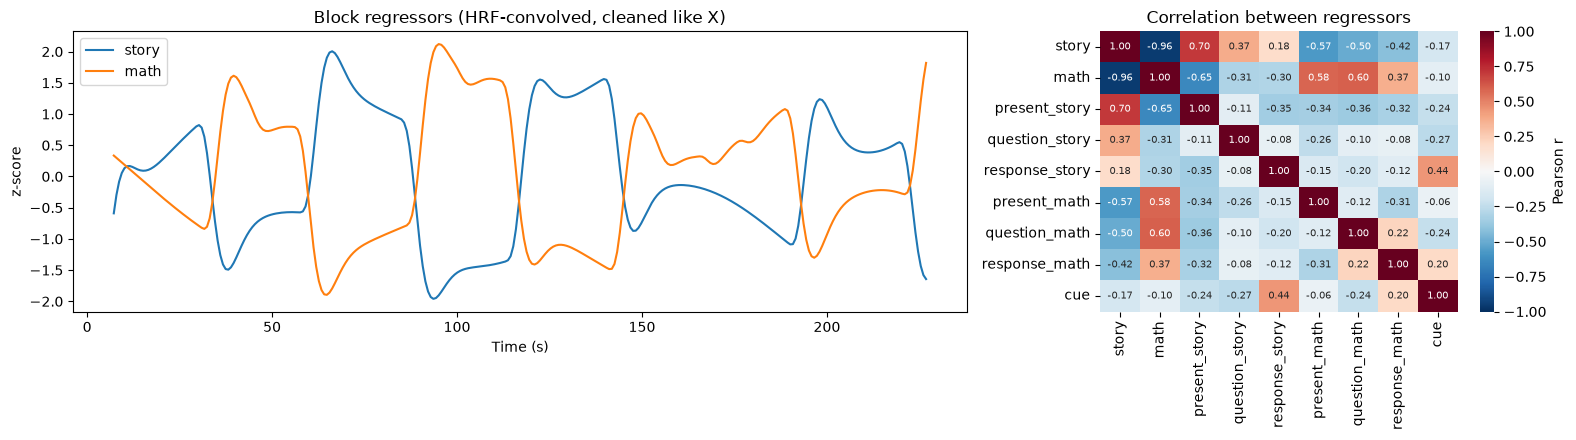

/var/folders/sx/7fj5c5s951545z9vqhwl9tvm0000gn/T/ipykernel_68709/2021011005.py:37: DeprecationWarning: The default strategy for standardize is currently 'zscore' which incorrectly uses population std to calculate sample zscores. The new strategy 'zscore_sample' corrects this behavior by using the sample std. In release 0.13, the default strategy will be replaced by the new strategy and the 'zscore' option will be removed. Please use 'zscore_sample' instead.
  mot_regs = pd.DataFrame(signal.clean(np.c_[mot, fd], detrend=True,


In [14]:
import seaborn as sns

BLOCKS = ["story", "math"]
SUB_TYPES = ["present_story", "question_story", "response_story",
             "present_math", "question_math", "response_math", "cue"]

blocks_dm = make_first_level_design_matrix(frame_times, events[events.trial_type.isin(BLOCKS)],
                                           hrf_model=HRF_MODEL, drift_model=None)[BLOCKS]
sub_dm = make_first_level_design_matrix(frame_times, events[events.trial_type.isin(SUB_TYPES)],
                                        hrf_model=HRF_MODEL, drift_model=None)[SUB_TYPES]

# Same volumes removed as in the data, then same cleaning as X (detrend + cosine drifts + z-score)
raw_regs = pd.concat([blocks_dm, sub_dm], axis=1).iloc[N_DROP:]
regs = pd.DataFrame(signal.clean(raw_regs.values, detrend=True,
                                 confounds=dm_clean[drift_cols].values,
                                 standardize="zscore_sample", t_r=TR),
                    index=ft_clean, columns=raw_regs.columns)
print("Regressors:", regs.shape, regs.columns.tolist())


fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1]})
for b in BLOCKS:
    ax[0].plot(ft_clean, regs[b], label=b)
ax[0].set(xlabel="Time (s)", ylabel="z-score", title="Block regressors (HRF-convolved, cleaned like X)")
ax[0].legend()
sns.heatmap(regs.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            annot_kws={"size": 7}, cbar_kws={"label": "Pearson r"}, ax=ax[1])
ax[1].set_title("Correlation between regressors")
plt.tight_layout(); plt.savefig(op.join(OUT_DIR, "regressors.png"), dpi=150); plt.show()

# Motion regressors (6 + FD)im
TASK_COLS = list(regs.columns)
if op.exists(MOTION_PATH):
    mot = pd.read_csv(MOTION_PATH, sep=r"\s+", header=None).values
    fd = np.r_[0, np.abs(np.diff(mot, axis=0)) @ np.r_[50, 50, 50, 1, 1, 1]]
    MOTION_COLS = ["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z", "FD"]
    mot_regs = pd.DataFrame(signal.clean(np.c_[mot, fd], detrend=True,
                                         confounds=dm_clean[drift_cols].values,
                                         standardize="zscore_sample", t_r=TR),
                            index=ft_clean, columns=MOTION_COLS)
    regs = pd.concat([regs, mot_regs], axis=1)
else:
    print("Motion parameters not found: motion regressors skipped for now.")

## 12. IC time courses vs the story regressor
Blue: IC time course; grey: story regressor. **r** = correlation with story; **kurt** = kurtosis of the map (high = focal map, ≈ 0 = diffuse).

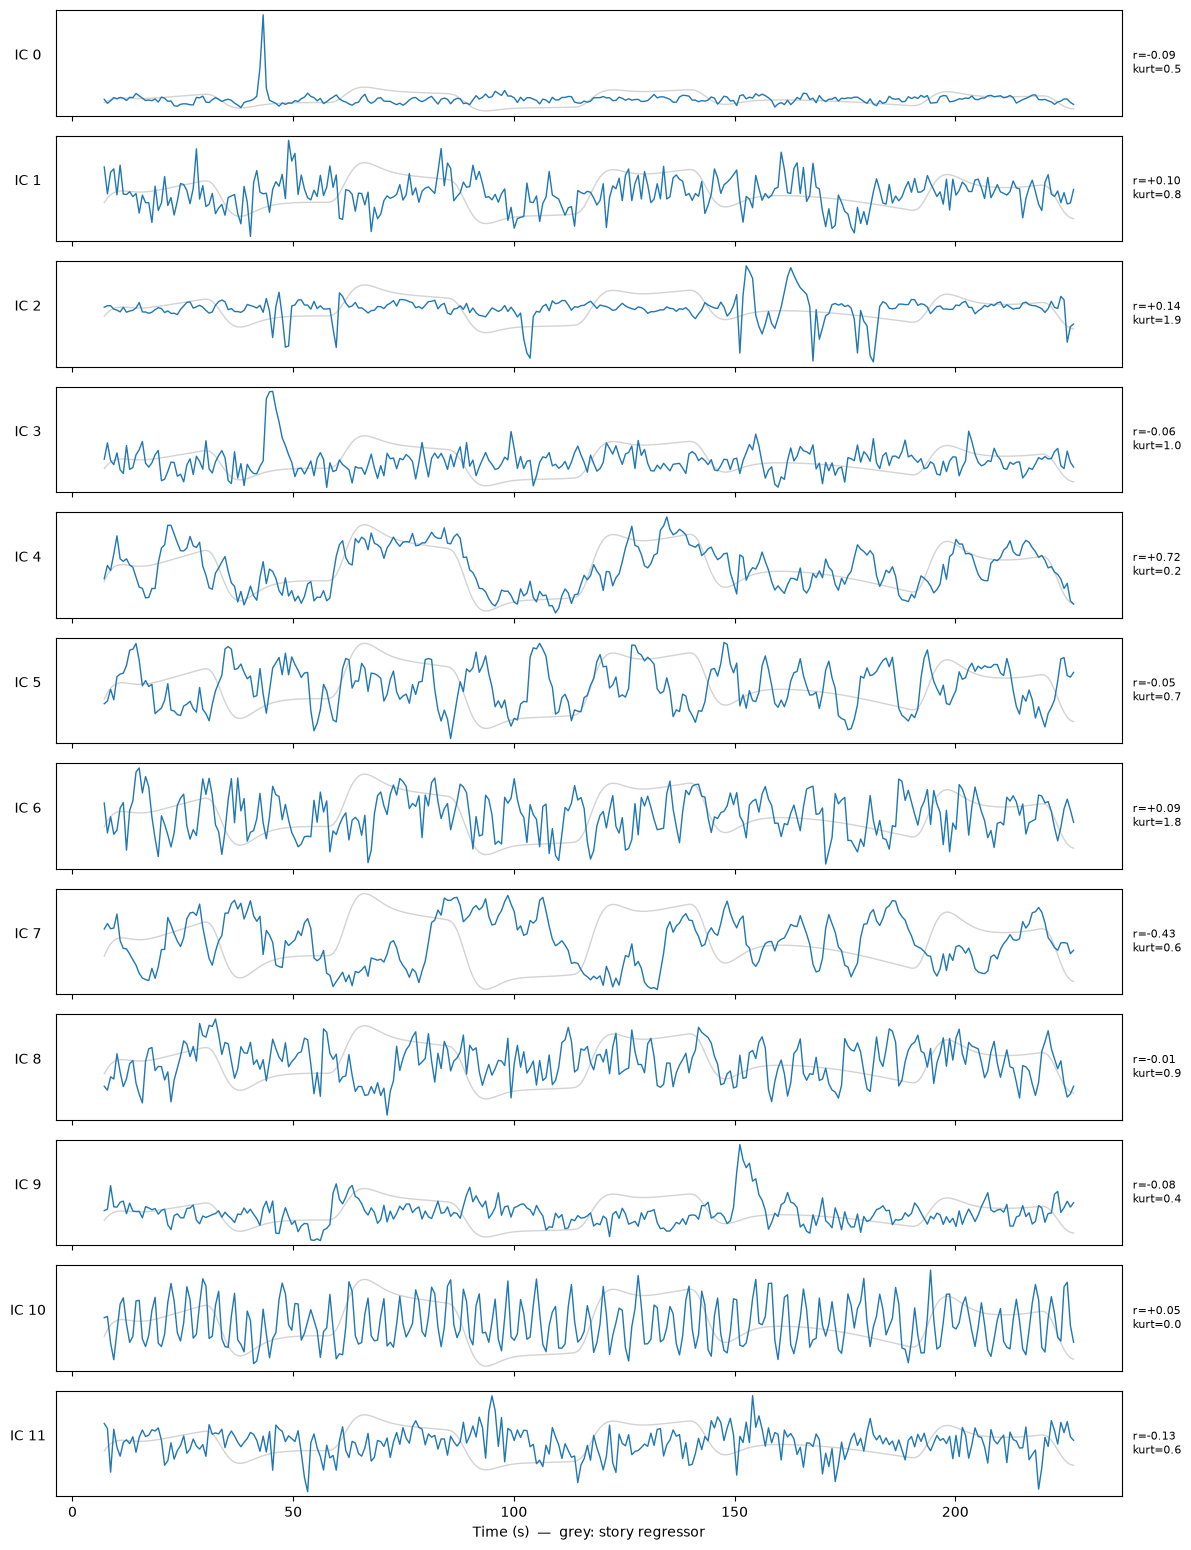

,r story,kurtosis,% voxels |z|>2.5
IC 0,-0.09,0.5,1.67
IC 1,0.10,0.8,2.28
IC 2,0.14,1.9,2.51
IC 3,-0.06,1.0,2.21
IC 4,0.72,0.2,1.61
IC 5,-0.05,0.7,2.19
IC 6,0.09,1.8,3.07
IC 7,-0.43,0.6,2.27
IC 8,-0.01,0.9,1.79
IC 9,-0.08,0.4,1.64


In [15]:
from scipy.stats import kurtosis

r_story = np.array([np.corrcoef(timecourses[:, i], regs["story"])[0, 1] for i in range(N_COMP)])
kurt = kurtosis(spatial_maps, axis=1)                  # excess kurtosis of each map
pct_supra = (np.abs(maps_z) > THRESH).mean(axis=1) * 100

fig, axes = plt.subplots(N_COMP, 1, figsize=(12, 1.3 * N_COMP), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(ft_clean, regs["story"], color="lightgray", lw=1)
    ax.plot(ft_clean, zscore(timecourses[:, i]), color="C0", lw=1)
    ax.set_ylabel(f"IC {i}", rotation=0, labelpad=20)
    ax.text(1.01, 0.5, f"r={r_story[i]:+.2f}\nkurt={kurt[i]:.1f}", transform=ax.transAxes,
            va="center", fontsize=8)
    ax.set_yticks([])
axes[-1].set_xlabel("Time (s)  —  grey: story regressor")
plt.tight_layout(); plt.savefig(op.join(OUT_DIR, f"ica{N_COMP}_timecourses.png"), dpi=150); plt.show()

ic_table = pd.DataFrame({"r story": r_story.round(2), "kurtosis": kurt.round(1),
                         f"% voxels |z|>{THRESH}": pct_supra.round(2)},
                        index=[f"IC {i}" for i in range(N_COMP)])
display(ic_table)

**Result.** IC 4 clearly follows the story regressor (r = 0.72): it rises during the story blocks and falls during the math blocks. IC 7 is anti-correlated with story (r = −0.43). The noise components look very different: IC 0 is flat except for a single peak (see §14), and IC 10 oscillates quickly and regularly, at about 0.27 Hz (16 cycles per minute), possibly breathing. The kurtosis values are low for all maps (≤ 1.9) and IC 4 is almost Gaussian (0.2): temporal ICA does not force the maps to be sparse, so the task maps are diffuse.

## 13. Correlation with the GLM regressors
Required matrix: **first 10 ICs** in FastICA order (IC 0–9). All components are shown in a second matrix (appendix). Vertical lines separate blocks | sub-phases | motion; task-related ICs are selected from task regressors only. Sign and order of ICs are arbitrary, so |r| is what matters; story and math are anti-correlated, so a story-related IC is usually negative with math.

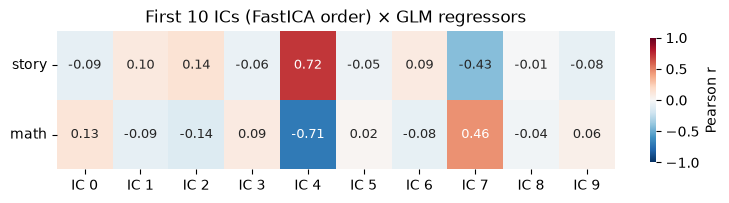

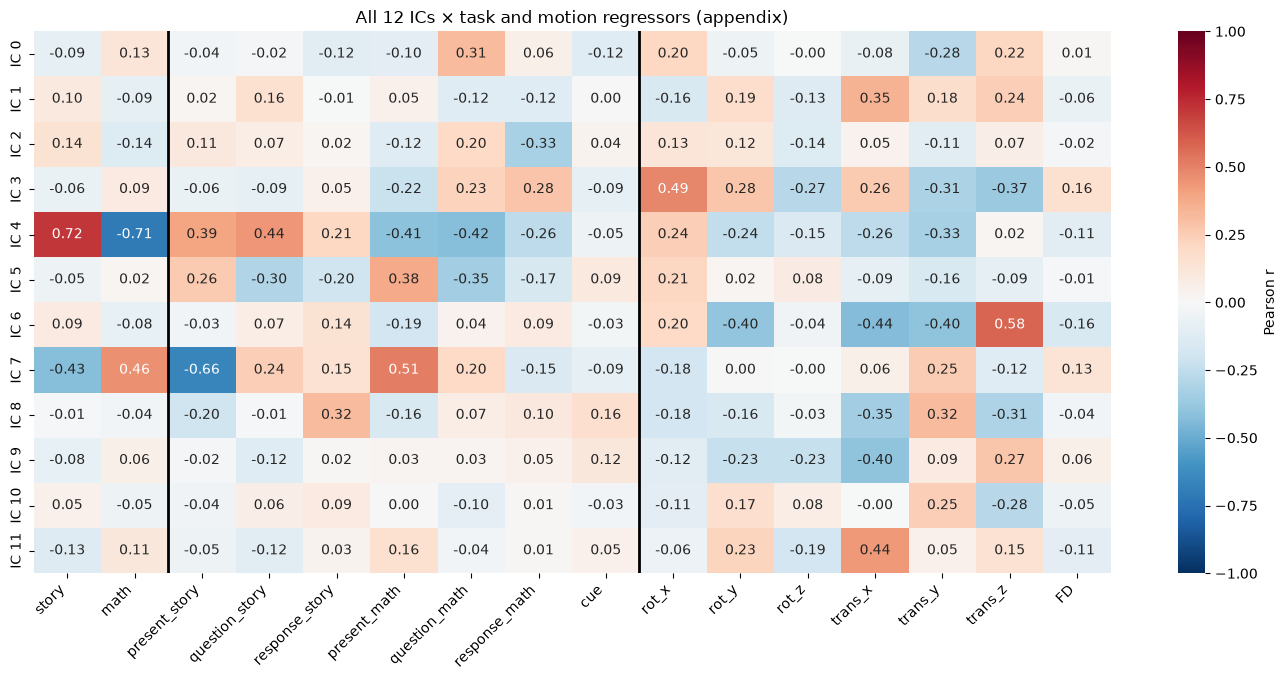

,|r| max,regressor,in first 10
IC 4,0.72,story,True
IC 7,0.66,present_story,True
IC 5,0.38,present_math,True
IC 2,0.33,response_math,True
IC 8,0.32,response_story,True
IC 0,0.31,question_math,True
IC 3,0.28,response_math,True
IC 6,0.19,present_math,True
IC 1,0.16,question_story,True
IC 11,0.16,present_math,False


,best IC,r
story,IC 4,0.72
math,IC 4,-0.71
present_story,IC 7,-0.66
question_story,IC 4,0.44
response_story,IC 8,0.32
present_math,IC 7,0.51
question_math,IC 4,-0.42
response_math,IC 2,-0.33
cue,IC 8,0.16
rot_x,IC 3,0.49


In [16]:
def corr_ic_regs(tc, regs):
    n = tc.shape[1]
    C = np.corrcoef(tc.T, regs.values.T)[:n, n:]
    return pd.DataFrame(C, index=[f"IC {i}" for i in range(n)], columns=regs.columns)

def plot_corr(C, title, fname):
    fig, ax = plt.subplots(figsize=(14, 0.45 * len(C) + 1.5))
    sns.heatmap(C, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                cbar_kws={"label": "Pearson r"}, ax=ax)
    ax.axvline(len(BLOCKS), color="black", lw=2)              # blocks | sub-phases
    if C.shape[1] > len(TASK_COLS):
        ax.axvline(len(TASK_COLS), color="black", lw=2)       # task | motion
    ax.set_title(title)
    plt.xticks(rotation=45, ha="right"); plt.tight_layout()
    fig.savefig(op.join(OUT_DIR, fname), dpi=200, bbox_inches="tight")
    plt.show()

# Required matrix: first 10 ICs x GLM regressors (story, math), transposed for a compact figure
C10 = corr_ic_regs(timecourses[:, :10], regs[BLOCKS])         # (10 ICs, 2 regressors)
fig, ax = plt.subplots(figsize=(9, 1.8))
sns.heatmap(C10.T, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            annot_kws={"size": 9}, cbar_kws={"label": "Pearson r", "shrink": 0.9}, ax=ax)
ax.set_title("First 10 ICs (FastICA order) × GLM regressors")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
fig.savefig(op.join(OUT_DIR, f"ica{N_COMP}_corr_first10.png"), dpi=200, bbox_inches="tight")
plt.show()

# Full matrix (appendix): all ICs x GLM blocks, sub-phases and motion
C_all = corr_ic_regs(timecourses, regs)
plot_corr(C_all, f"All {N_COMP} ICs × task and motion regressors (appendix)",
          f"ica{N_COMP}_corr_all.png")

# Summary: best task regressor for each IC, and best IC for each regressor
summary = pd.DataFrame({"|r| max": C_all[TASK_COLS].abs().max(axis=1).round(2),
                        "regressor": C_all[TASK_COLS].abs().idxmax(axis=1),
                        "in first 10": [i < 10 for i in range(N_COMP)]}
                       ).sort_values("|r| max", ascending=False)
display(summary)
best_ic = pd.DataFrame({"best IC": C_all.abs().idxmax(axis=0),
                        "r": [C_all.loc[C_all[c].abs().idxmax(), c].round(2) for c in C_all.columns]})
display(best_ic)

### Analysis of the correlations

The sign and order of the components are arbitrary, so only |r| and the pattern of signs matter. Since `story` and `math` alternate, a block-related component always has opposite correlations with the two regressors.

**GLM regressors (required matrix).** Only two of the first 10 components follow the blocks: **IC 4** (r = 0.72 with `story`, −0.71 with `math`) and, more weakly, **IC 7** (r = −0.43 and 0.46). All others have |r| ≤ 0.14.

**Sub-phases (full matrix).** They refine this picture:
- **IC 4** is positive during every phase of the stories and negative during every phase of the math problems: it follows the sustained state of each block, like the story − math contrast of the GLM.
- **IC 7** is mostly tied to the presentation phase (−0.66 with `present_story`, 0.51 with `present_math`): it distinguishes listening to a story from listening to a math problem.
- **IC 5** is invisible with the blocks (|r| ≤ 0.05) but follows the same pattern in both tasks: positive while listening (0.26 and 0.38), negative during the question (−0.30 and −0.35).

**Motion.** Most remaining components follow the head motion parameters, e.g. IC 6 with the z translation (r = 0.58), IC 3 with the x rotation (0.49) and IC 11 with the x translation (0.44). Each motion parameter is best explained by a noise component, never by a task component. IC 2 is unrelated to motion (|r| ≤ 0.14), consistent with a physiological origin. The task components are moderately correlated with motion (IC 4: up to |r| = 0.33), which is checked in §14.

## 14. Motion checks
Two checks on the role of head motion. First, IC 0 consists of a single peak: we compare its position with the framewise displacement (FD) computed from the MCFLIRT parameters. FD at volume k measures the movement between volumes k − 1 and k.

In [17]:
fd_raw = np.r_[0, np.abs(np.diff(mot, axis=0)) @ np.r_[50, 50, 50, 1, 1, 1]]
i0 = np.argmax(np.abs(timecourses[:, 0]))
print(f"IC 0 peak : volume {i0} ({ft_clean[i0]:.1f} s)")
print(f"FD max    : volume {np.argmax(fd_raw)} ({ft_clean[np.argmax(fd_raw)]:.1f} s), {fd_raw.max():.2f} mm")
print("FD around the IC 0 peak:", np.round(fd_raw[max(i0 - 2, 0):i0 + 3], 2))

IC 0 peak : volume 50 (43.2 s)
FD max    : volume 51 (43.9 s), 0.34 mm
FD around the IC 0 peak: [0.02 0.21 0.05 0.34 0.11]


**Result.** The peak of IC 0 is at volume 50 (43 s), framed by the two largest FD values of the run: 0.21 mm at volume 49 and 0.34 mm at volume 51. This is a move-and-return pattern: the head moves, stays one volume in the displaced position, and moves back. IC 0 is therefore a motion artefact, even though its correlation with FD is close to zero (r = 0.01): FD peaks at the transitions, not at the displaced volume, so a correlation cannot capture such a brief event.

Second, the task components are moderately correlated with motion (§13). To check that their link with the task is not driven by motion, we regress the six motion parameters and FD out of both the IC time course and the task regressor, and recompute the correlation (partial correlation).

In [18]:
from numpy.linalg import lstsq
M = np.c_[np.ones(len(regs)), regs[MOTION_COLS].values]
resid = lambda y: y - M @ lstsq(M, y, rcond=None)[0]

print("Motion vs story:\n", regs[MOTION_COLS].corrwith(regs["story"]).round(2).to_string(), "\n")
for i, reg in [(4, "story"), (7, "story"), (5, "present_math"), (5, "question_math")]:
    r_raw = np.corrcoef(timecourses[:, i], regs[reg])[0, 1]
    r_part = np.corrcoef(resid(timecourses[:, i]), resid(regs[reg].values))[0, 1]
    print(f"IC {i} / {reg:13s}: r = {r_raw:+.2f} -> after removing motion = {r_part:+.2f}")
    

Motion vs story:
 rot_x      0.22
rot_y     -0.16
rot_z     -0.09
trans_x   -0.24
trans_y   -0.32
trans_z    0.09
FD        -0.12 

IC 4 / story        : r = +0.72 -> after removing motion = +0.67
IC 7 / story        : r = -0.43 -> after removing motion = -0.38
IC 5 / present_math : r = +0.38 -> after removing motion = +0.50
IC 5 / question_math: r = -0.35 -> after removing motion = -0.34


**Result.** Head motion is weakly correlated with the task (|r| ≤ 0.32 with `story`, mostly the y translation), so the subject moved slightly differently during stories and math. This explains the moderate correlation of the task components with motion. After removing motion, the correlations remain almost unchanged (IC 4 with `story`: 0.72 → 0.67; IC 7: −0.43 → −0.38; IC 5 with `question_math`: −0.35 → −0.34), and the link of IC 5 with `present_math` even becomes stronger (0.38 → 0.50). The relation of the task components to the task is therefore not explained by motion. The same task-correlated motion also concerns the GLM of Part 1.

## Conclusion
Without any information about the task, temporal ICA recovered the main GLM effect in a single component (IC 4, story versus math), separated phases within each trial (IC 7 and IC 5), and isolated most artefacts (motion and physiological noise) into separate components. These results are descriptive: they rest on a single run of a single subject, the correlations are not statistical tests (the time courses are autocorrelated), and the physiological origin of IC 2 and IC 10 could not be confirmed without cardiac and respiratory recordings.